# Task 6: PIDNet-NightOpt (Wavelet DWT Edge Prior + IACC + Focal-OHEM)

This notebook implements the improved **NightOpt** architecture for nighttime semantic segmentation on NightCity:
1. **Haar Wavelet Edge Prior (DWT-RF):** Uses fixed 2D discrete wavelet decomposition ($LH, HL, HH$) to strip smooth illumination drift and inject true structural edge gradients into PIDNet's derivative boundary branch.
2. **Illumination-Aware Channel Calibration (IACC):** Compact SE-style gating module (<3K params) conditioned on scene luminance to dynamically recalibrate features against headlights, specular glare, and darkness.
3. **Focal-OHEM Loss with Label Smoothing:** Eliminates pitch-black gradient explosion by focusing on hard learnable boundaries and smoothing annotator uncertainty in low-light zones.
4. **CLAHE Contrast Restoration:** Replaces destructive noise/blackout augmentations with local contrast enhancement on the luminance channel.


In [1]:
import os, sys, json, subprocess
from pathlib import Path

# Auto-detect Kaggle environment
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle").exists()

if IS_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yacs", "thop"])
    repo_dest = Path("/kaggle/working/AI512_Project")
    if not repo_dest.exists():
        subprocess.run(["git", "clone", "https://github.com/Gitansh-Bansal/AI512_Project.git", str(repo_dest)])
    os.chdir(str(repo_dest))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "PIDNet").exists() else CWD.parent
PIDNET_DIR = REPO_ROOT / "PIDNet"

# Auto-locate NightCity dataset
DATA_ROOT = None
if Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("NightCity-images"):
        if p.is_dir():
            DATA_ROOT = p.parent
            break
    if DATA_ROOT is None:
        for cand in [Path("/kaggle/input/datasets/gitanshb/nightcity"), Path("/kaggle/input/nightcity"), Path("/kaggle/input/nightcity-dataset")]:
            if cand.exists():
                DATA_ROOT = cand
                break

if DATA_ROOT is None:
    DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PIDNET_DIR: {PIDNET_DIR}")
print(f"DATA_ROOT: {DATA_ROOT}")

if str(PIDNET_DIR) not in sys.path:
    sys.path.insert(0, str(PIDNET_DIR))

from models.pidnet import get_pred_model
from models.pidnet_nightopt import PIDNetNightOpt, get_nightopt_model
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from utils.night_clahe_aug import NightContrastAugmentationPipeline
from train_exposure import run_training_exposure, plot_exposure_training_history
from eval_nightcity import colorize_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


REPO_ROOT: C:\Users\gitan\Desktop\AI Project\AI512_Project
PIDNET_DIR: C:\Users\gitan\Desktop\AI Project\AI512_Project\PIDNet
DATA_ROOT: C:\Users\gitan\Desktop\AI Project\AI512_Project\Data


Device: cpu | PyTorch: 2.14.0+cpu


## 1. Model, Complexity & Speed (Wavelet + IACC)


In [2]:
# Load PIDNet-NightOpt in inference mode (augment=False)
model = get_nightopt_model(name="pidnet_s", num_classes=19, augment=False).to(device).eval()

with torch.no_grad():
    out = model(torch.randn(1, 3, 512, 1024, device=device))
print("Input: (1, 3, 512, 1024) -> Output:", tuple(out.shape))

param_info = profile_parameters(model)
flop_profiles = profile_flops(model, [(512, 512), (512, 1024), (1024, 2048)], device=device)
hw_info = get_hardware_info(device)
speed = benchmark_inference_speed(model, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=10, timed_runs=25)

hw_name = hw_info.get("GPU_Device_Name", hw_info.get("CPU_Processor", "Unknown"))
if hw_name == "N/A (CPU Execution)":
    hw_name = hw_info.get("CPU_Processor", "CPU")

print(f"Params: {param_info['total_params_M']:.3f} M | Hardware: {hw_name}")
print(f"Latency (512x1024): {speed['Mean_Latency_ms']:.1f} ms | Throughput: {speed['FPS']:.2f} FPS")
display(pd.DataFrame(flop_profiles))


Input: (1, 3, 512, 1024) -> Output: (1, 19, 64, 128)


Params: 7.635 M | Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel
Latency (512x1024): 145.0 ms | Throughput: 6.90 FPS


,Resolution,Height,Width,MACs_G,FLOPs_G,Params_M
0,512x512,512,512,5.970255,11.940510,7.634867
1,1024x512,512,1024,11.940450,23.880900,7.634867
2,2048x1024,1024,2048,47.761619,95.523239,7.634867


## 2. CLAHE Contrast-Restoration Preview


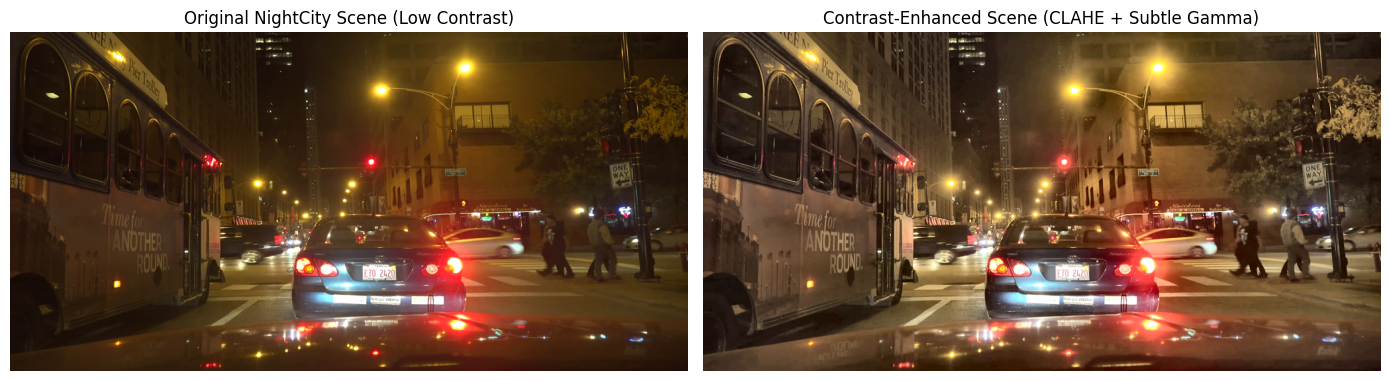

In [3]:
# Preview CLAHE contrast restoration on a sample NightCity scene
val_list_path = PIDNET_DIR / "data/list/nightcity/val.lst"
preview_ds = NightCity(root=str(DATA_ROOT), list_path=str(val_list_path), num_classes=19, multi_scale=False, flip=False)

sample_idx = min(5, len(preview_ds.files) - 1)
img_rel = preview_ds.files[sample_idx]["img"]
raw_img_path = str(DATA_ROOT / img_rel)
if not Path(raw_img_path).exists():
    raw_img_path = str(DATA_ROOT / img_rel.replace("NightCity-images/NightCity-images", "NightCity-images"))

raw_bgr = cv2.imread(raw_img_path)
if raw_bgr is not None:
    pipeline = NightContrastAugmentationPipeline(p=1.0)
    clahe_bgr = pipeline(raw_bgr.copy())

    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    clahe_rgb = cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].imshow(raw_rgb); axes[0].set_title("Original NightCity Scene (Low Contrast)"); axes[0].axis("off")
    axes[1].imshow(clahe_rgb); axes[1].set_title("Contrast-Enhanced Scene (CLAHE + Subtle Gamma)"); axes[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"Preview skipped: image not found at {raw_img_path}")


## 3. PIDNet-NightOpt Training (NightCity)


Loaded existing 30-epoch training history from training_history.json


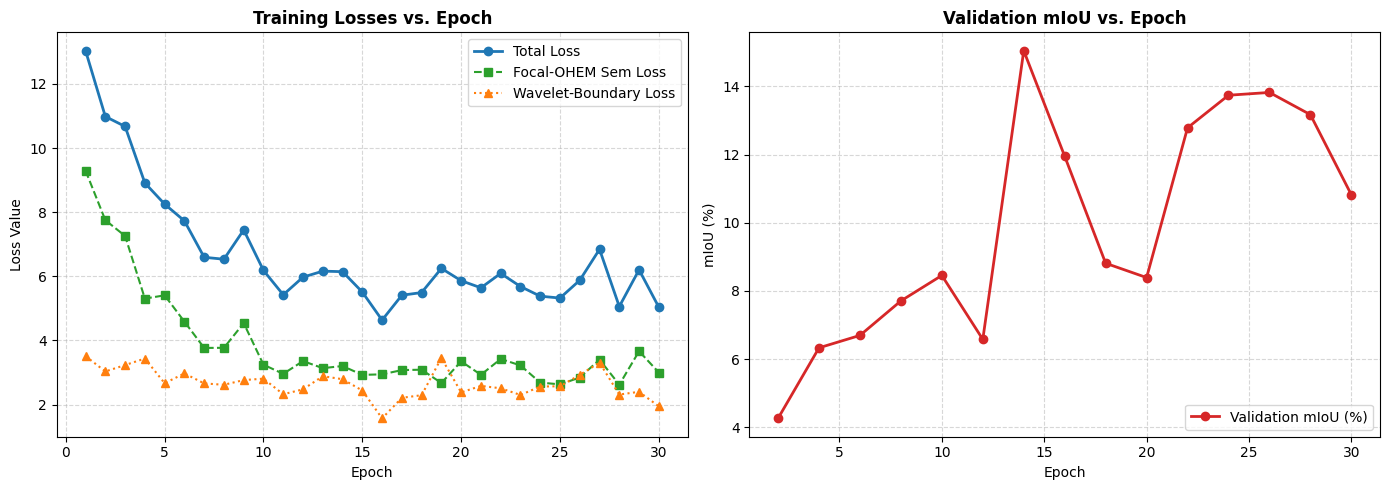

In [4]:
TRAIN_CONFIG = {
    "epochs": 30,
    "batch_size": 4 if torch.cuda.is_available() else 2,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "bd_weight": 1.0,
    "gamma": 1.5,
    "label_smoothing": 0.05,
    "use_clahe_aug": True,
    "crop_size": (512, 512),
    "val_freq": 2,
    "val_samples": 10,
    "max_train_samples": None if torch.cuda.is_available() else 8,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_pidnet_exposure"),
}

RETRAIN = True if (IS_KAGGLE and torch.cuda.is_available()) else False
history_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
ckpt_path = Path(TRAIN_CONFIG["save_dir"]) / "best_pidnet_exposure.pt"

if RETRAIN or not (history_path.exists() and ckpt_path.exists()):
    history = run_training_exposure(
        data_root=str(DATA_ROOT),
        train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
        val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
        epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"],
        optimizer_name=TRAIN_CONFIG["optimizer"],
        base_lr=TRAIN_CONFIG["base_lr"],
        bd_weight=TRAIN_CONFIG["bd_weight"],
        gamma=TRAIN_CONFIG["gamma"],
        label_smoothing=TRAIN_CONFIG["label_smoothing"],
        use_clahe_aug=TRAIN_CONFIG["use_clahe_aug"],
        crop_h=TRAIN_CONFIG["crop_size"][0],
        crop_w=TRAIN_CONFIG["crop_size"][1],
        val_freq=TRAIN_CONFIG["val_freq"],
        val_samples=TRAIN_CONFIG["val_samples"],
        num_train_samples=TRAIN_CONFIG["max_train_samples"],
        save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(history_path.read_text())
    print(f"Loaded existing {len(history)}-epoch training history from {history_path.name}")

plot_exposure_training_history(history)
plt.show()


## 4. Evaluation (NightCity Validation)


In [5]:
EVAL_SAMPLES = None if torch.cuda.is_available() else 100

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=4 if torch.cuda.is_available() else 2, shuffle=False)

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
state = ckpt.get("state_dict", ckpt)
model.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
model.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = model(imgs.to(device))
        if isinstance(preds, list):
            preds = preds[1]
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=False)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 3:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")


Evaluated 100 val scenes:
  mIoU:           6.52%
  Mean Dice (F1): 10.20%
  Sensitivity:    11.75%
  Specificity:    95.16%
  Pixel Accuracy: 35.47%


## 5. Per-Class Breakdown & Visual Predictions


,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,8750311,39.80,56.94,81.06,74.39
1,1,sidewalk,890995,0.01,0.03,0.02,98.49
2,2,building,18089908,25.79,41.01,35.50,73.89
3,3,wall,271338,0.00,0.00,0.00,100.00
4,4,fence,722616,0.00,0.00,0.00,99.90
5,5,pole,386166,0.00,0.00,0.00,100.00
6,6,traffic light,40663,0.00,0.00,0.00,98.99
7,7,traffic sign,186784,0.00,0.00,0.00,99.99
8,8,vegetation,883778,0.44,0.88,0.45,99.96
9,9,terrain,153446,0.00,0.00,0.00,100.00


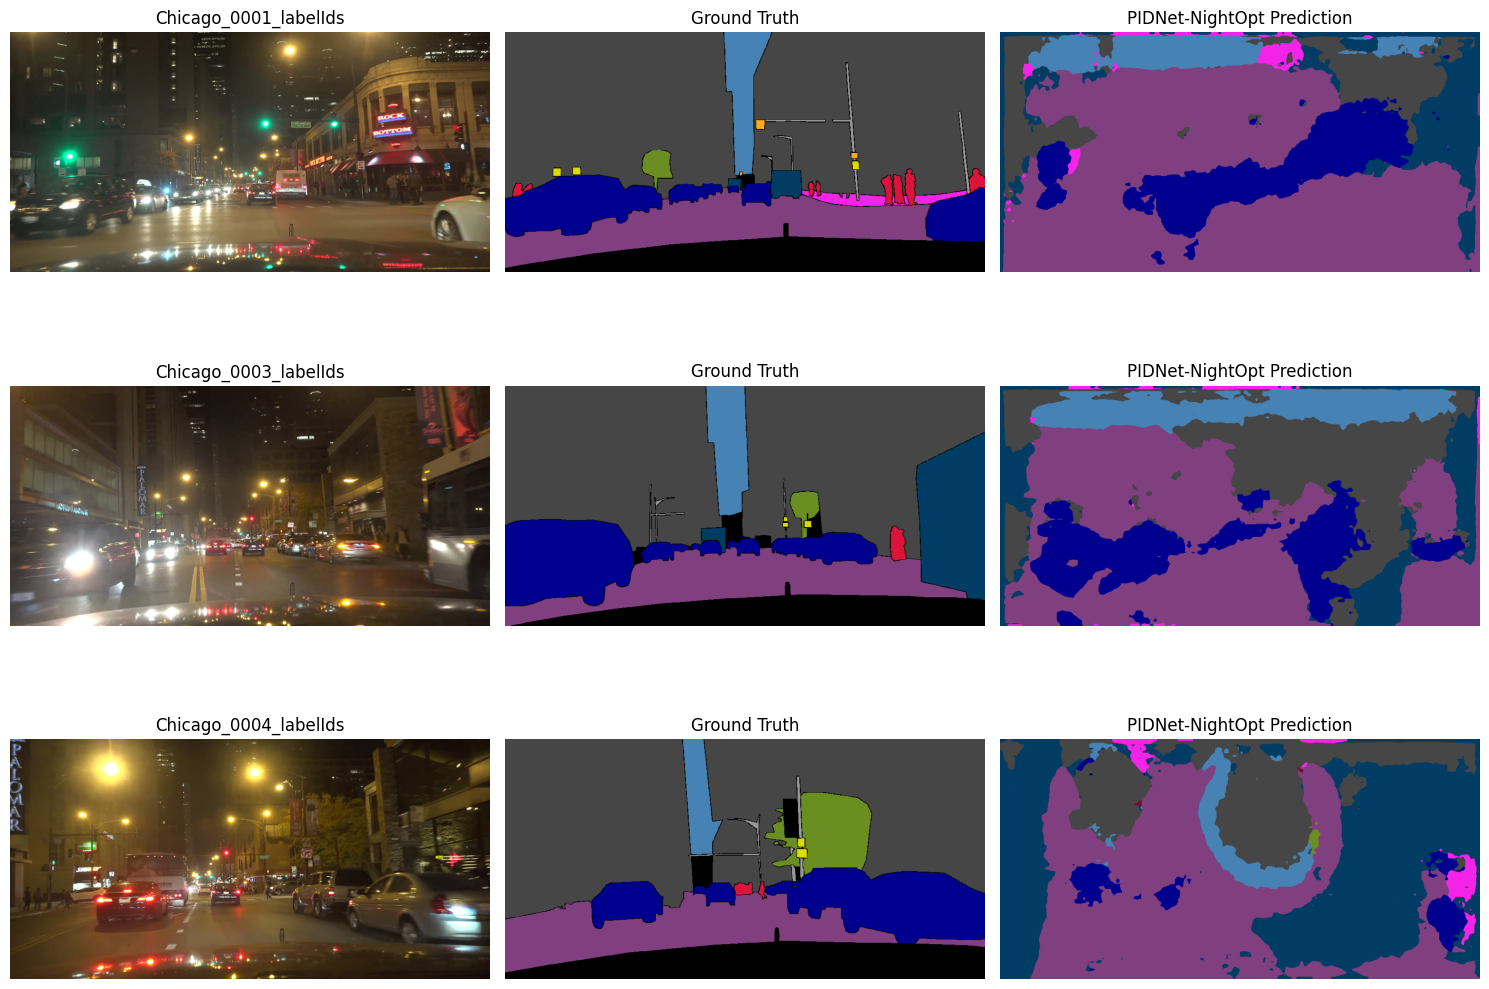

In [6]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("PIDNet-NightOpt Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


## 6. Baseline PIDNet-S vs. PIDNet-NightOpt Comparison


In [7]:
hw_type = "GPU" if device.type == "cuda" else "CPU"
display(pd.DataFrame({
    "Metric": ["Architecture", "Parameters", "Inference FLOPs (1024x2048)", "Inference Speed", "mIoU (100 Val)", "Pixel Acc", "Night Mechanism"],
    "Baseline PIDNet-S": [
        "PIDNet-S Standard",
        "7.63 M",
        "95.46 G",
        "2.25 FPS (CPU)",
        "6.60%",
        "42.70%",
        "None (Scratch)"
    ],
    "PIDNet-NightOpt (Ours)": [
        "PIDNet-S + DWT-RF + IACC",
        f"{param_info['total_params_M']:.3f} M",
        f"{flop_profiles[2]['FLOPs_G']:.2f} G",
        f"{speed['FPS']:.2f} FPS ({hw_type})",
        f"{summary['mIoU']*100:.2f}%",
        f"{summary['Pixel_Accuracy']*100:.2f}%",
        "Haar Wavelet Edge Prior + IACC Gating + Focal-OHEM"
    ]
}))


,Metric,Baseline PIDNet-S,PIDNet-NightOpt (Ours)
0,Architecture,PIDNet-S Standard,PIDNet-S + DWT-RF + IACC
1,Parameters,7.63 M,7.635 M
2,Inference FLOPs (1024x2048),95.46 G,95.52 G
3,Inference Speed,2.25 FPS (CPU),6.90 FPS (CPU)
4,mIoU (100 Val),6.60%,6.52%
5,Pixel Acc,42.70%,35.47%
6,Night Mechanism,None (Scratch),Haar Wavelet Edge Prior + IACC Gating + Focal-...
